### Dataset Uploads and Libraries


In [58]:
# CELL 1 – Imports
from pathlib import Path
import pickle
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
rng_global = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)

In [59]:
# CELL 2 – Upload ZIP files
from google.colab import files
import os
import zipfile
from pathlib import Path

BASE = Path("/content/Assignment8")
BASE.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        print("\nExtracting:", filename)
        with zipfile.ZipFile(filename, "r") as zip_ref:
            for member in zip_ref.infolist():
                target = (BASE / member.filename).resolve()
                if not target.is_relative_to(BASE.resolve()):
                    raise ValueError(f"Unsafe path in ZIP archive: {member.filename}")
            zip_ref.extractall(BASE)

print("\nZIP extraction completed.")
print("Extracted dataset directory:", BASE)


Saving Image Feature Dataset.zip to Image Feature Dataset (1).zip
Saving MNIST.zip to MNIST (1).zip
Saving SyntheticData.zip to SyntheticData (1).zip
Saving TIDIGIT.zip to TIDIGIT (1).zip

Extracting: Image Feature Dataset (1).zip

Extracting: MNIST (1).zip

Extracting: SyntheticData (1).zip

Extracting: TIDIGIT (1).zip

ZIP extraction completed.
Extracted dataset directory: /content/Assignment8


In [60]:
# CELL 3 – Dataset paths and verification
from pathlib import Path
BASE = Path("/content/Assignment8")

SYNTHETIC_FILE = BASE / "SyntheticData" / "team12" / "data.pkl"
MNIST_ROOT = BASE / "MNIST" / "TEAM_12"
TIDIGITS_ROOT = BASE / "TIDIGIT" / "Data"
IMAGE_ROOT = BASE / "Image Feature Dataset" / "team12"

paths = {
    "SyntheticData": SYNTHETIC_FILE,
    "MNIST": MNIST_ROOT,
    "TIDIGITS": TIDIGITS_ROOT,
    "Image Feature Dataset": IMAGE_ROOT,
}

print("Dataset path verification\n")
for name, path in paths.items():
    print(f"{name:24s}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print("Path:", path)
    print()

missing = [name for name, path in paths.items() if not path.exists()]
if missing:
    raise FileNotFoundError("These dataset paths were not found: " + ", ".join(missing) + ". Check that each ZIP contains the expected top-level folder.")
print("All four dataset paths are ready.")


Dataset path verification

SyntheticData           : FOUND
Path: /content/Assignment8/SyntheticData/team12/data.pkl

MNIST                   : FOUND
Path: /content/Assignment8/MNIST/TEAM_12

TIDIGITS                : FOUND
Path: /content/Assignment8/TIDIGIT/Data

Image Feature Dataset   : FOUND
Path: /content/Assignment8/Image Feature Dataset/team12

All four dataset paths are ready.


In [61]:
# CELL 4 – General data utilities
def stratified_split(X, y, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    """Split fixed-length data class-by-class; test receives the remainder."""
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for label in np.unique(y):
        idx = np.where(y == label)[0]
        rng.shuffle(idx)
        n_train = int(len(idx) * train_ratio)
        n_val = int(len(idx) * val_ratio)
        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train+n_val])
        test_idx.extend(idx[n_train+n_val:])
    rng.shuffle(train_idx); rng.shuffle(val_idx); rng.shuffle(test_idx)
    return (X[train_idx], y[train_idx],
            X[val_idx], y[val_idx],
            X[test_idx], y[test_idx])

def accuracy_score_manual(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

def show_class_counts(name, y):
    labels, counts = np.unique(y, return_counts=True)
    print(name, dict(zip(labels.tolist(), counts.tolist())))

def standardize_fit(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    std[std < 1e-10] = 1.0
    return mean, std

def standardize_transform(X, mean, std):
    return (X - mean) / std

def prepare_standardized(train_X, *other_X):
    mean, std = standardize_fit(train_X)
    result = [standardize_transform(train_X, mean, std)]
    result.extend(standardize_transform(x, mean, std) for x in other_X)
    return result

def confusion_matrix_manual(y_true, y_pred):
    labels = np.unique(np.concatenate([y_true, y_pred]))
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    label_to_index = {label: i for i, label in enumerate(labels)}

    for actual, predicted in zip(y_true, y_pred):
        i = label_to_index[actual]
        j = label_to_index[predicted]
        matrix[i, j] += 1
    return labels, matrix

### Principal Component Analysis (PCA)




In [62]:
# CELL 5 – PCA
class ManualPCA:
    def __init__(self, n_components):
        self.n_components = int(n_components)

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        covariance = (Xc.T @ Xc) / max(1, len(Xc) - 1)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        order = np.argsort(eigenvalues)[::-1]
        self.eigenvalues_ = eigenvalues[order]
        self.components_ = eigenvectors[:, order[:self.n_components]]
        total = np.sum(self.eigenvalues_)
        self.explained_variance_ratio_ = (
            self.eigenvalues_[:self.n_components] / total if total > 0
            else np.zeros(self.n_components)
        )
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=np.float64) - self.mean_) @ self.components_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def choose_pca_dimensions(n_features):
    candidates = [5, 10, 20, 50, 100]
    values = sorted(set(min(k, n_features) for k in candidates))
    return [k for k in values if 1 <= k < n_features]

### Gaussian Mixture Model (GMM)

In [63]:
# CELL 6 – GMM
def logsumexp(a, axis=1):
    a_max = np.max(a, axis=axis, keepdims=True)
    result = a_max + np.log(np.sum(np.exp(a - a_max), axis=axis, keepdims=True) + 1e-300)
    return np.squeeze(result, axis=axis)


class DiagonalGMM:
    def __init__(self, n_components=2, max_iter=25, tol=1e-3, reg=1e-4, seed=SEED):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.reg = reg
        self.seed = seed

    def _component_log_probability(self, X):
        diff = X[:, None, :] - self.means_[None, :, :]
        d = X.shape[1]
        return -0.5 * (
            d * np.log(2.0 * np.pi)
            + np.sum(np.log(self.variances_), axis=1)[None, :]
            + np.sum((diff ** 2) / self.variances_[None, :, :], axis=2)
        ) + np.log(self.weights_[None, :] + 1e-300)

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        n, d = X.shape
        k = min(self.n_components, n)
        rng = np.random.default_rng(self.seed)
        chosen = rng.choice(n, size=k, replace=False)
        self.means_ = X[chosen].copy()
        global_var = np.var(X, axis=0) + self.reg
        self.variances_ = np.tile(global_var, (k, 1))
        self.weights_ = np.full(k, 1.0 / k)
        previous_ll = -np.inf

        for _ in range(self.max_iter):
            log_joint = self._component_log_probability(X)
            log_norm = logsumexp(log_joint, axis=1)
            responsibilities = np.exp(log_joint - log_norm[:, None])
            nk = responsibilities.sum(axis=0) + 1e-10

            self.weights_ = nk / n
            self.means_ = (responsibilities.T @ X) / nk[:, None]
            for j in range(k):
                diff = X - self.means_[j]
                self.variances_[j] = (np.sum(responsibilities[:, j, None] * (diff ** 2), axis=0) / nk[j] + self.reg)

            current_ll = float(np.mean(log_norm))
            if abs(current_ll - previous_ll) < self.tol:
                break
            previous_ll = current_ll
        return self

    def score_samples(self, X):
        return logsumexp(self._component_log_probability(np.asarray(X, dtype=np.float64)), axis=1)


class ClassConditionalGMM:
    def __init__(self, n_components=2, max_iter=25):
        self.n_components = n_components
        self.max_iter = max_iter

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = []
        self.log_priors_ = []
        for i, label in enumerate(self.classes_):
            Xc = X[y == label]
            model = DiagonalGMM( n_components=self.n_components, max_iter=self.max_iter, seed=SEED + i ).fit(Xc)
            self.models_.append(model)
            self.log_priors_.append(np.log(len(Xc) / len(X)))
        self.log_priors_ = np.asarray(self.log_priors_)
        return self

    def predict(self, X):
        scores = np.column_stack([model.score_samples(X) + self.log_priors_[i] for i, model in enumerate(self.models_)])
        return self.classes_[np.argmax(scores, axis=1)]

### Linear Discriminant Analysis (LDA)

In [64]:
# CELL 7 – LDA
class ManualLDA:
    def __init__(self, regularization=1e-4):
        self.regularization = regularization

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n, d = X.shape
        c = len(self.classes_)
        Sw = np.zeros((d, d), dtype=np.float64)
        self.means_ = []
        self.priors_ = []

        for label in self.classes_:
            Xc = X[y == label]
            mean_c = Xc.mean(axis=0)
            self.means_.append(mean_c)
            self.priors_.append(len(Xc) / n)
            centered = Xc - mean_c
            Sw += centered.T @ centered
        self.means_ = np.asarray(self.means_)
        self.priors_ = np.asarray(self.priors_)
        pooled_cov = Sw / (n - c)        # Pooled covariance

        # Regularization
        scale = np.trace(pooled_cov) / d
        pooled_cov += (self.regularization * max(scale, 1.0) * np.eye(d))
        self.A_ = np.linalg.solve(pooled_cov, self.means_.T)
        self.bias_ = (-0.5 * np.sum( self.means_ * self.A_.T, axis=1) + np.log(self.priors_ + 1e-12))
        return self

    def predict(self, X):
        scores = np.asarray(X) @ self.A_ + self.bias_
        return self.classes_[np.argmax(scores, axis=1)]

### K-Nearest Neighbors (KNN)


In [65]:
# CELL 8 – KNN
class ManualKNN:
    def __init__(self, k=5, chunk_size=256):
        self.k = k
        self.chunk_size = chunk_size

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=np.float64)
        self.y_train_ = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        predictions = []
        k = min(self.k, len(self.X_train_))
        train_norm = np.sum(self.X_train_ ** 2, axis=1)

        for start in range(0, len(X), self.chunk_size):
            batch = X[start:start+self.chunk_size]
            distances = (
                np.sum(batch ** 2, axis=1)[:, None]
                + train_norm[None, :]
                - 2.0 * batch @ self.X_train_.T
            )
            nearest = np.argpartition(distances, kth=k-1, axis=1)[:, :k]
            for row in nearest:
                labels, counts = np.unique(self.y_train_[row], return_counts=True)
                predictions.append(labels[np.argmax(counts)])
        return np.asarray(predictions)

### Linear Support Vector Machine (SVM)

In [66]:
# CELL 9 – Linear SVM using one-vs-rest hinge-loss gradient descent
class ManualLinearSVM:
    def __init__(self, learning_rate=0.01, epochs=25, C=0.05, batch_size=256, seed=SEED):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.C = C
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n, d = X.shape
        self.W_ = np.zeros((len(self.classes_), d))
        self.b_ = np.zeros(len(self.classes_))
        rng = np.random.default_rng(self.seed)

        # One binary classifier per class (one-vs-rest).
        Y = np.where(y[:, None] == self.classes_[None, :], 1.0, -1.0)
        for epoch in range(self.epochs):
            order = rng.permutation(n)
            rate = self.learning_rate / (1.0 + 0.03 * epoch)
            for start in range(0, n, self.batch_size):
                idx = order[start:start+self.batch_size]
                Xb, Yb = X[idx], Y[idx]
                margins = Yb * (Xb @ self.W_.T + self.b_[None, :])
                active = margins < 1.0
                grad_W = self.W_ - self.C * (active * Yb).T @ Xb / len(idx)
                grad_b = -self.C * np.sum(active * Yb, axis=0) / len(idx)
                self.W_ -= rate * grad_W
                self.b_ -= rate * grad_b
        return self

    def predict(self, X):
        scores = np.asarray(X) @ self.W_.T + self.b_[None, :]
        return self.classes_[np.argmax(scores, axis=1)]

### Dynamic Time Warping (DTW)

In [67]:
# CELL 10 – DTW dynamic programming for variable-length sequences
def resample_sequence(sequence, target_frames=40):
    """Linearly resample one sequence along its time axis."""
    sequence = np.asarray(sequence, dtype=np.float64)
    old_t = np.linspace(0.0, 1.0, len(sequence))
    new_t = np.linspace(0.0, 1.0, target_frames)
    result = np.empty((target_frames, sequence.shape[1]), dtype=np.float64)
    for j in range(sequence.shape[1]):
        result[:, j] = np.interp(new_t, old_t, sequence[:, j])
    return result

def dtw_distance(A, B, window=8):
    """DTW with squared Euclidean local cost and a Sakoe-Chiba window."""
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    n, m = len(A), len(B)
    w = max(window, abs(n - m))
    previous = np.full(m + 1, np.inf)
    previous[0] = 0.0

    for i in range(1, n + 1):
        current = np.full(m + 1, np.inf)
        j_start = max(1, i - w)
        j_end = min(m, i + w)
        for j in range(j_start, j_end + 1):
            cost = np.sum((A[i-1] - B[j-1]) ** 2)
            current[j] = cost + min(
                previous[j],       # insertion
                current[j-1],      # deletion
                previous[j-1]     # match
            )
        previous = current
    return previous[m] / max(n + m, 1)

class ManualDTWClassifier:
    """Nearest-prototype DTW classifier; prototypes are selected from training only."""
    def __init__(self, prototypes_per_class=25, target_frames=40, window=8, seed=SEED):
        self.prototypes_per_class = prototypes_per_class
        self.target_frames = target_frames
        self.window = window
        self.seed = seed

    def fit(self, sequences, labels):
        rng = np.random.default_rng(self.seed)
        self.classes_ = np.unique(labels)
        self.prototypes_ = []
        self.prototype_labels_ = []
        for label in self.classes_:
            idx = np.where(np.asarray(labels) == label)[0]
            chosen = rng.choice(idx, size=min(self.prototypes_per_class, len(idx)), replace=False)
            for i in chosen:
                self.prototypes_.append(resample_sequence(sequences[i], self.target_frames))
                self.prototype_labels_.append(label)
        self.prototype_labels_ = np.asarray(self.prototype_labels_)
        return self

    def predict(self, sequences):
        predictions = []
        for sequence in sequences:
            query = resample_sequence(sequence, self.target_frames)
            distances = np.asarray([
                dtw_distance(query, prototype, self.window)
                for prototype in self.prototypes_
            ])
            nearest = np.argmin(distances)
            predictions.append(self.prototype_labels_[nearest])
        return np.asarray(predictions)

### Loading Data

In [68]:
# CELL 11 – Dataset loading: SyntheticData
with open(SYNTHETIC_FILE, "rb") as f:
    synthetic = pickle.load(f)

X_syn = np.asarray(synthetic["x"], dtype=np.float64)
y_syn = np.asarray(synthetic["y"], dtype=int)
syn_train_X, syn_train_y, syn_val_X, syn_val_y, syn_test_X, syn_test_y = stratified_split(
    X_syn, y_syn, seed=SEED
)
print("Synthetic:", X_syn.shape, "classes:", np.unique(y_syn))
show_class_counts("Synthetic train", syn_train_y)
show_class_counts("Synthetic validation", syn_val_y)
show_class_counts("Synthetic test", syn_test_y)

Synthetic: (20000, 16) classes: [0 1]
Synthetic train {0: 7000, 1: 7000}
Synthetic validation {0: 1500, 1: 1500}
Synthetic test {0: 1500, 1: 1500}


In [69]:
# CELL 12 – Dataset loading: Image Feature Dataset
def read_csv_matrix(path):
    return pd.read_csv(path, header=None).to_numpy(dtype=np.float64)

X_img_train = read_csv_matrix(IMAGE_ROOT / "train_data.csv")
y_img_train = read_csv_matrix(IMAGE_ROOT / "train_label.csv").ravel().astype(int)
X_img_val = read_csv_matrix(IMAGE_ROOT / "val_data.csv")
y_img_val = read_csv_matrix(IMAGE_ROOT / "val_label.csv").ravel().astype(int)
X_img_test = read_csv_matrix(IMAGE_ROOT / "test_data.csv")
y_img_test = read_csv_matrix(IMAGE_ROOT / "test_label.csv").ravel().astype(int)

print("Image Feature Dataset:", X_img_train.shape, X_img_val.shape, X_img_test.shape)
show_class_counts("Image train", y_img_train)
show_class_counts("Image validation", y_img_val)
show_class_counts("Image test", y_img_test)

Image Feature Dataset: (2000, 36) (500, 36) (500, 36)
Image train {0: 400, 1: 400, 2: 400, 3: 400, 4: 400}
Image validation {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}
Image test {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}


In [70]:
# CELL 13 – Dataset loading: MNIST image folders
def load_mnist_split(split_path):
    """Read class-folder images: split/1/*.png, split/6/*.png, split/9/*.png."""
    images, labels = [], []
    for class_dir in sorted(p for p in split_path.iterdir() if p.is_dir()):
        try:
            label = int(class_dir.name)
        except ValueError:
            continue
        for file in sorted(class_dir.iterdir()):
            if file.suffix.lower() not in {".png", ".jpg", ".jpeg", ".bmp"}:
                continue
            image = Image.open(file).convert("L").resize((28, 28))
            arr = np.asarray(image, dtype=np.float64) / 255.0
            images.append(arr.reshape(-1))
            labels.append(label)
    if not images:
        raise FileNotFoundError(f"No digit images found under {split_path}")
    return np.vstack(images), np.asarray(labels, dtype=int)

X_mnist_train, y_mnist_train = load_mnist_split(MNIST_ROOT / "train")
X_mnist_test, y_mnist_test = load_mnist_split(MNIST_ROOT / "test")
X_mnist_val, y_mnist_val = load_mnist_split(MNIST_ROOT / "dev")

print("MNIST:", X_mnist_train.shape, X_mnist_val.shape, X_mnist_test.shape)
show_class_counts("MNIST train", y_mnist_train)
show_class_counts("MNIST validation", y_mnist_val)
show_class_counts("MNIST test", y_mnist_test)

MNIST: (14911, 784) (3698, 784) (3102, 784)
MNIST train {1: 5383, 6: 4752, 9: 4776}
MNIST validation {1: 1359, 6: 1166, 9: 1173}
MNIST test {1: 1135, 6: 958, 9: 1009}


In [71]:
# CELL 14 – Dataset loading: TIDIGITS sequences
# Team 12 mapping line is: 12 : [6, 1, 7]
TIDIGITS_LABELS = [6, 1, 7]

def load_tidigits_sequences(root, labels=TIDIGITS_LABELS, seed=SEED):
    """Each NPZ arr_i is one (frames, 39) utterance. Split utterances per digit."""
    rng = np.random.default_rng(seed)
    train_seq, train_y = [], []
    val_seq, val_y = [], []
    test_seq, test_y = [], []

    for label in labels:
        archive_path = root / f"{label}.npz"
        if not archive_path.exists():
            raise FileNotFoundError(f"Missing TIDIGITS file: {archive_path}")
        archive = np.load(archive_path, allow_pickle=True)
        utterances = [np.asarray(archive[key], dtype=np.float64) for key in archive.files]
        idx = rng.permutation(len(utterances))
        n_train = int(0.70 * len(idx))
        n_val = int(0.15 * len(idx))
        groups = [
            (idx[:n_train], train_seq, train_y),
            (idx[n_train:n_train+n_val], val_seq, val_y),
            (idx[n_train+n_val:], test_seq, test_y),
        ]
        for selected, seq_out, label_out in groups:
            for i in selected:
                seq = utterances[i]
                if seq.ndim != 2 or seq.shape[1] != 39:
                    raise ValueError(f"Expected (frames, 39), got {seq.shape} in {archive_path}")
                seq_out.append(seq)
                label_out.append(label)

    return (train_seq, np.asarray(train_y),
            val_seq, np.asarray(val_y),
            test_seq, np.asarray(test_y))


def pool_sequence(sequence, segments=4):
    """Fixed-length representation: mean and standard deviation in time segments."""
    sequence = np.asarray(sequence, dtype=np.float64)
    pooled = []
    boundaries = np.linspace(0, len(sequence), segments + 1, dtype=int)
    for i in range(segments):
        part = sequence[boundaries[i]:boundaries[i+1]]
        if len(part) == 0:
            part = sequence
        pooled.extend(part.mean(axis=0))
        pooled.extend(part.std(axis=0))
    return np.asarray(pooled, dtype=np.float64)


def pool_sequences(sequences):
    return np.vstack([pool_sequence(s) for s in sequences])

tid_train_seq, tid_train_y, tid_val_seq, tid_val_y, tid_test_seq, tid_test_y = (
    load_tidigits_sequences(TIDIGITS_ROOT)
)
X_tid_train = pool_sequences(tid_train_seq)
X_tid_val = pool_sequences(tid_val_seq)
X_tid_test = pool_sequences(tid_test_seq)

print("TIDIGITS sequences:", len(tid_train_seq), len(tid_val_seq), len(tid_test_seq))
print("TIDIGITS pooled features:", X_tid_train.shape, X_tid_val.shape, X_tid_test.shape)
show_class_counts("TIDIGITS train", tid_train_y)
show_class_counts("TIDIGITS validation", tid_val_y)
show_class_counts("TIDIGITS test", tid_test_y)

TIDIGITS sequences: 945 201 204
TIDIGITS pooled features: (945, 312) (201, 312) (204, 312)
TIDIGITS train {1: 315, 6: 315, 7: 315}
TIDIGITS validation {1: 67, 6: 67, 7: 67}
TIDIGITS test {1: 68, 6: 68, 7: 68}


### GMM, LDA, KNN, SVM (Without PCA)

In [72]:
# CELL 15 – Common evaluation function for GMM, LDA, KNN and SVM
def evaluate_four_classifiers(
    X_train, y_train, X_eval, y_eval,
    verbose=True, return_predictions=False
):
    Xtr, Xev = prepare_standardized(X_train, X_eval)
    results = {}
    predictions = {}

    start = time.time()
    gmm = ClassConditionalGMM(n_components=2, max_iter=20).fit(Xtr, y_train)
    pred = gmm.predict(Xev)
    predictions["GMM"] = pred
    results["GMM"] = accuracy_score_manual(y_eval, pred)
    if verbose:
        print(f"GMM: {results['GMM']:.4f} ({time.time()-start:.1f}s)")

    start = time.time()
    lda = ManualLDA().fit(Xtr, y_train)
    pred = lda.predict(Xev)
    predictions["LDA"] = pred
    results["LDA"] = accuracy_score_manual(y_eval, pred)
    if verbose:
        print(f"LDA: {results['LDA']:.4f} ({time.time()-start:.1f}s)")

    start = time.time()
    knn = ManualKNN(k=5).fit(Xtr, y_train)
    pred = knn.predict(Xev)
    predictions["KNN"] = pred
    results["KNN"] = accuracy_score_manual(y_eval, pred)
    if verbose:
        print(f"KNN: {results['KNN']:.4f} ({time.time()-start:.1f}s)")

    start = time.time()
    svm = ManualLinearSVM(
        learning_rate=0.01, epochs=25, C=0.05
    ).fit(Xtr, y_train)
    pred = svm.predict(Xev)
    predictions["SVM"] = pred
    results["SVM"] = accuracy_score_manual(y_eval, pred)
    if verbose:
        print(f"SVM: {results['SVM']:.4f} ({time.time()-start:.1f}s)")

    if return_predictions:
        return results, predictions

    return results

In [73]:
# CELL 16 – Run the original-feature experiments
datasets = {
    "Synthetic": (syn_train_X, syn_train_y, syn_test_X, syn_test_y),
    "MNIST": (X_mnist_train, y_mnist_train, X_mnist_test, y_mnist_test),
    "TIDIGITS": (X_tid_train, tid_train_y, X_tid_test, tid_test_y),
    "Image Features": (X_img_train, y_img_train, X_img_test, y_img_test),
}

original_results = {}
original_predictions = {}
for name, (Xtr, ytr, Xte, yte) in datasets.items():
    print("\n" + "="*65 + "\n", name, "\n" + "="*65)
    original_results[name], original_predictions[name] = (
    evaluate_four_classifiers(
        Xtr, ytr, Xte, yte,
        return_predictions=True
    )
)

# DTW is specifically evaluated on the sequential TIDIGITS dataset.
print("\nTIDIGITS – DTW")
dtw_model = ManualDTWClassifier(prototypes_per_class=25, target_frames=40, window=8)
dtw_model.fit(tid_train_seq, tid_train_y)
dtw_predictions = dtw_model.predict(tid_test_seq)
dtw_accuracy = accuracy_score_manual(tid_test_y, dtw_predictions)
print(f"DTW: {dtw_accuracy:.4f}")


 Synthetic 
GMM: 0.9867 (0.1s)
LDA: 0.9797 (0.0s)
KNN: 0.9987 (0.6s)
SVM: 0.9310 (0.2s)

 MNIST 
GMM: 0.9668 (9.5s)
LDA: 0.9861 (0.3s)
KNN: 0.9903 (2.4s)
SVM: 0.9774 (2.4s)

 TIDIGITS 
GMM: 0.9755 (0.1s)
LDA: 1.0000 (0.0s)
KNN: 0.9902 (0.0s)
SVM: 0.9118 (0.1s)

 Image Features 
GMM: 0.5980 (0.1s)
LDA: 0.6260 (0.0s)
KNN: 0.5540 (0.0s)
SVM: 0.4980 (0.0s)

TIDIGITS – DTW
DTW: 0.9902


### GMM, LDA, KNN, SVM, DTW[Only for TIDIGITS] (With PCA)

In [74]:
# CELL 17 – Repeat experiments after PCA using top-K components
# PCA is fitted only on the training feature matrix.
pca_results = []
pca_predictions = {}

for name, (Xtr_raw, ytr, Xte_raw, yte) in datasets.items():
    print("\nPCA experiments:", name)
    for k in choose_pca_dimensions(Xtr_raw.shape[1]):
        pca = ManualPCA(n_components=k).fit(Xtr_raw)
        Xtr_pca = pca.transform(Xtr_raw)
        Xte_pca = pca.transform(Xte_raw)
        scores, predictions = evaluate_four_classifiers(Xtr_pca, ytr, Xte_pca, yte, verbose=False, return_predictions=True)
        pca_predictions[(name, k)] = predictions
        row = {"Dataset": name, "PCA components": k, **scores}
        pca_results.append(row)
        print(f"K={k:3d} | " + " | ".join(f"{m}={v:.4f}" for m, v in scores.items()))

pca_results_df = pd.DataFrame(pca_results)
display(pca_results_df)


PCA experiments: Synthetic
K=  5 | GMM=0.9683 | LDA=0.9403 | KNN=0.9727 | SVM=0.9403
K= 10 | GMM=0.9773 | LDA=0.9597 | KNN=0.9933 | SVM=0.9593

PCA experiments: MNIST
K=  5 | GMM=0.9810 | LDA=0.9639 | KNN=0.9855 | SVM=0.9010
K= 10 | GMM=0.9839 | LDA=0.9797 | KNN=0.9907 | SVM=0.9181
K= 20 | GMM=0.9848 | LDA=0.9871 | KNN=0.9932 | SVM=0.9452
K= 50 | GMM=0.9765 | LDA=0.9890 | KNN=0.9948 | SVM=0.9626
K=100 | GMM=0.9861 | LDA=0.9894 | KNN=0.9855 | SVM=0.9639

PCA experiments: TIDIGITS
K=  5 | GMM=0.9853 | LDA=0.9706 | KNN=0.9902 | SVM=0.9657
K= 10 | GMM=0.9902 | LDA=0.9804 | KNN=0.9853 | SVM=0.9755
K= 20 | GMM=0.9902 | LDA=0.9804 | KNN=0.9902 | SVM=0.9804
K= 50 | GMM=0.9902 | LDA=0.9951 | KNN=0.8873 | SVM=0.9951
K=100 | GMM=0.9951 | LDA=0.9902 | KNN=0.8186 | SVM=0.9951

PCA experiments: Image Features
K=  5 | GMM=0.5860 | LDA=0.5280 | KNN=0.4600 | SVM=0.5060
K= 10 | GMM=0.6140 | LDA=0.5760 | KNN=0.5280 | SVM=0.5400
K= 20 | GMM=0.6000 | LDA=0.6260 | KNN=0.4880 | SVM=0.5960


,Dataset,PCA components,GMM,LDA,KNN,SVM
0,Synthetic,5,0.968333,0.940333,0.972667,0.940333
1,Synthetic,10,0.977333,0.959667,0.993333,0.959333
2,MNIST,5,0.980980,0.963894,0.985493,0.901032
3,MNIST,10,0.983881,0.979691,0.990651,0.918117
4,MNIST,20,0.984848,0.987105,0.993230,0.945197
5,MNIST,50,0.976467,0.989039,0.994842,0.962605
6,MNIST,100,0.986138,0.989362,0.985493,0.963894
7,TIDIGITS,5,0.985294,0.970588,0.990196,0.965686
8,TIDIGITS,10,0.990196,0.980392,0.985294,0.975490
9,TIDIGITS,20,0.990196,0.980392,0.990196,0.980392


In [75]:
# CELL 18 – PCA + DTW for TIDIGITS
# Fit PCA on training frames only, then project each utterance frame-by-frame.
all_train_frames = np.vstack(tid_train_seq)
dtw_pca_results = []
dtw_pca_predictions = {}

for k in [5, 10, 20, 30]:
    k = min(k, all_train_frames.shape[1])
    frame_pca = ManualPCA(n_components=k).fit(all_train_frames)

    train_projected = [frame_pca.transform(s) for s in tid_train_seq]
    test_projected = [frame_pca.transform(s) for s in tid_test_seq]

    model = ManualDTWClassifier(
        prototypes_per_class=25, target_frames=40, window=8, seed=SEED
    ).fit(train_projected, tid_train_y)
    pred = model.predict(test_projected)
    dtw_pca_predictions[k] = pred
    score = accuracy_score_manual(tid_test_y, pred)
    dtw_pca_results.append({"Dataset": "TIDIGITS", "PCA components": k, "DTW": score})
    print(f"DTW with PCA K={k}: {score:.4f}")

display(pd.DataFrame(dtw_pca_results))

DTW with PCA K=5: 0.9902
DTW with PCA K=10: 0.9951
DTW with PCA K=20: 0.9902
DTW with PCA K=30: 0.9902


,Dataset,PCA components,DTW
0,TIDIGITS,5,0.990196
1,TIDIGITS,10,0.995098
2,TIDIGITS,20,0.990196
3,TIDIGITS,30,0.990196


### Accuracy

In [76]:
# CELL 19 – Accuracy comparison tables
original_table = pd.DataFrame(original_results).T
original_table.loc["TIDIGITS", "DTW"] = dtw_accuracy
print("Original feature-space test accuracy")
display((100 * original_table).round(2).astype(str) + "%")

print("PCA test accuracy")
display(
    pca_results_df.assign(**{
        col: 100 * pca_results_df[col]
        for col in ["GMM", "LDA", "KNN", "SVM"]
    }).round(2)
)

print("TIDIGITS DTW with PCA")
display(pd.DataFrame(dtw_pca_results).assign(
    DTW=lambda d: 100 * d["DTW"]
).round(2))

Original feature-space test accuracy


,GMM,LDA,KNN,SVM,DTW
Synthetic,98.67%,97.97%,99.87%,93.1%,nan%
MNIST,96.68%,98.61%,99.03%,97.74%,nan%
TIDIGITS,97.55%,100.0%,99.02%,91.18%,99.02%
Image Features,59.8%,62.6%,55.4%,49.8%,nan%


PCA test accuracy


,Dataset,PCA components,GMM,LDA,KNN,SVM
0,Synthetic,5,96.83,94.03,97.27,94.03
1,Synthetic,10,97.73,95.97,99.33,95.93
2,MNIST,5,98.10,96.39,98.55,90.10
3,MNIST,10,98.39,97.97,99.07,91.81
4,MNIST,20,98.48,98.71,99.32,94.52
5,MNIST,50,97.65,98.90,99.48,96.26
6,MNIST,100,98.61,98.94,98.55,96.39
7,TIDIGITS,5,98.53,97.06,99.02,96.57
8,TIDIGITS,10,99.02,98.04,98.53,97.55
9,TIDIGITS,20,99.02,98.04,99.02,98.04


TIDIGITS DTW with PCA


,Dataset,PCA components,DTW
0,TIDIGITS,5,99.02
1,TIDIGITS,10,99.51
2,TIDIGITS,20,99.02
3,TIDIGITS,30,99.02


### Plotting and Confusion Matrix

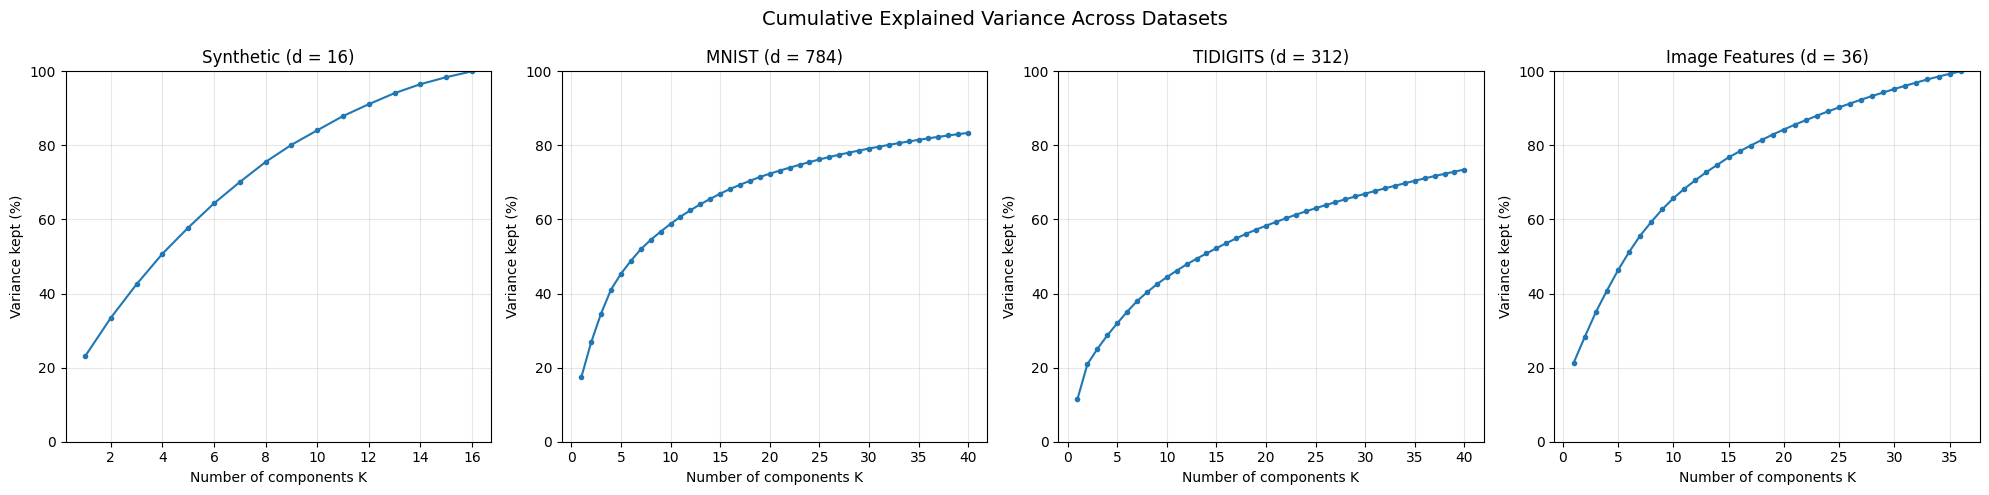

Synthetic          {2: 33.4, 5: 57.8, 10: 84.1} (% variance kept)
MNIST              {2: 26.8, 5: 45.3, 10: 58.8, 20: 72.4, 40: 83.4} (% variance kept)
TIDIGITS           {2: 20.9, 5: 32.0, 10: 44.4, 20: 58.3, 40: 73.5} (% variance kept)
Image Features     {2: 28.3, 5: 46.3, 10: 65.7, 20: 84.3} (% variance kept)


In [77]:
# Cell 20 - PCA Cumulative Explained Variance Graph
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, (Xtr_raw, ytr, Xte_raw, yte)) in zip(axes, datasets.items()):
    max_components = min(40, Xtr_raw.shape[1], Xtr_raw.shape[0] - 1)

    pca_full = ManualPCA(n_components=max_components).fit(Xtr_raw)
    cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100
    k_values = np.arange(1, max_components + 1)

    ax.plot(
        k_values,
        cumulative_variance,
        marker="o",
        markersize=3
    )

    ax.set_title(f"{name} (d = {Xtr_raw.shape[1]})")
    ax.set_xlabel("Number of components K")
    ax.set_ylabel("Variance kept (%)")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)

plt.suptitle("Cumulative Explained Variance Across Datasets",fontsize=14)
plt.tight_layout()
plt.show()

# Print selected PCA variance values
for name, (Xtr_raw, ytr, Xte_raw, yte) in datasets.items():
    max_components = min(40, Xtr_raw.shape[1], Xtr_raw.shape[0] - 1)
    pca_full = ManualPCA(n_components=max_components).fit(Xtr_raw)
    cumulative = np.cumsum(pca_full.explained_variance_ratio_) * 100
    selected_k = [k for k in [2, 5, 10, 20, 40]if k <= max_components]
    values = {
        k: round(float(cumulative[k - 1]), 1)
        for k in selected_k
    }
    print(f"{name:18} {values} (% variance kept)")


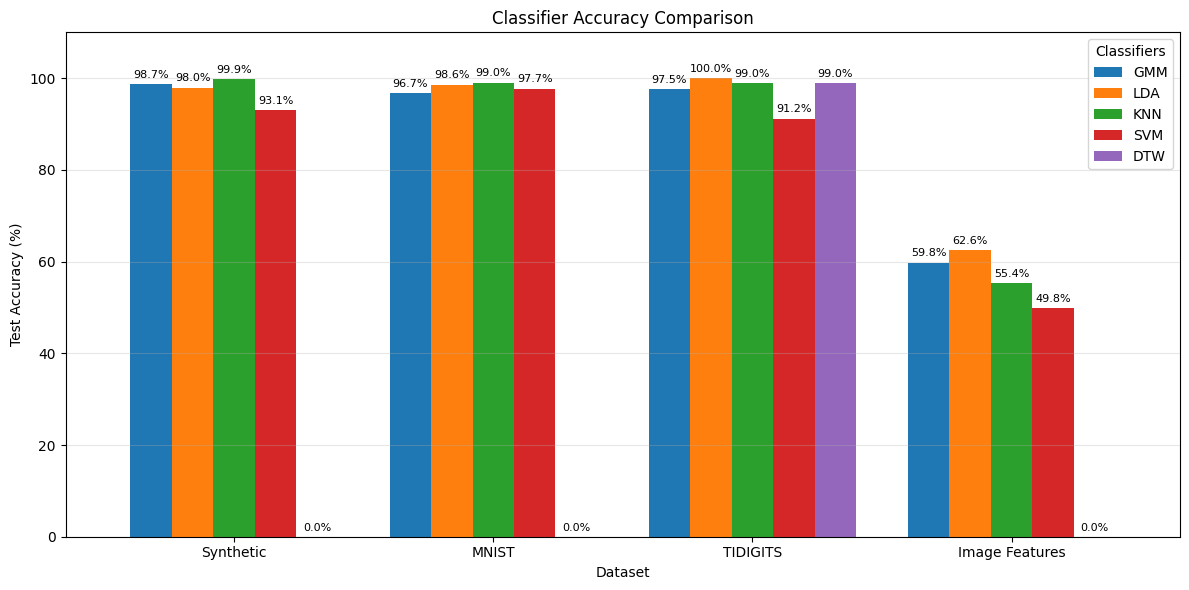

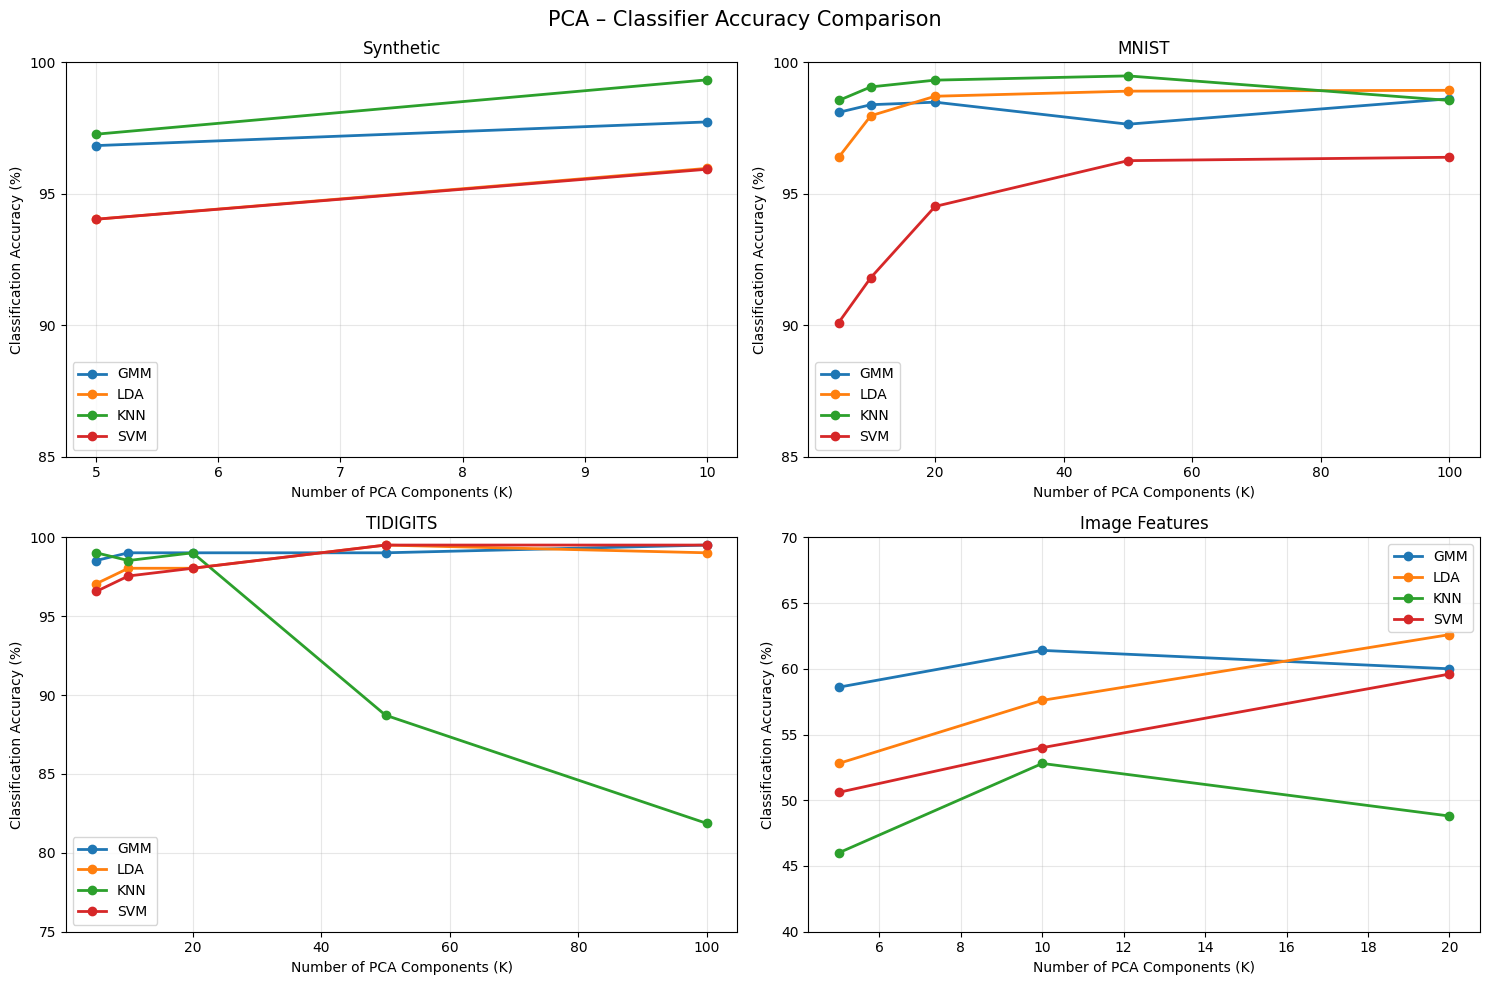


ORIGINAL DATA – CONFUSION MATRICES

Synthetic – GMM
Rows = Actual | Columns = Predicted
Class labels: [0 1]
[[1480   20]
 [  20 1480]]

Synthetic – LDA
Rows = Actual | Columns = Predicted
Class labels: [0 1]
[[1446   54]
 [   7 1493]]

Synthetic – KNN
Rows = Actual | Columns = Predicted
Class labels: [0 1]
[[1499    1]
 [   3 1497]]

Synthetic – SVM
Rows = Actual | Columns = Predicted
Class labels: [0 1]
[[1361  139]
 [  68 1432]]

MNIST – GMM
Rows = Actual | Columns = Predicted
Class labels: [1 6 9]
[[1068   19   48]
 [  12  944    2]
 [  15    7  987]]

MNIST – LDA
Rows = Actual | Columns = Predicted
Class labels: [1 6 9]
[[1130    3    2]
 [  12  945    1]
 [  20    5  984]]

MNIST – KNN
Rows = Actual | Columns = Predicted
Class labels: [1 6 9]
[[1127    6    2]
 [   4  953    1]
 [  15    2  992]]

MNIST – SVM
Rows = Actual | Columns = Predicted
Class labels: [1 6 9]
[[1127    7    1]
 [  25  930    3]
 [  25    9  975]]

TIDIGITS – GMM
Rows = Actual | Columns = Predicted
Class la

In [78]:
# CELL 21 – Original Accuracy, PCA Accuracy and Confusion Matrices
# PART A: ORIGINAL DATA – SINGLE GROUPED BAR CHART
ax = (100 * original_table).plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)
ax.set_ylabel("Test Accuracy (%)")
ax.set_xlabel("Dataset")
ax.set_title("Classifier Accuracy Comparison")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )
plt.xticks(rotation=0)
plt.legend(title="Classifiers")
plt.tight_layout()
plt.show()

# PART B: PCA Classifier Accuracy
classifiers = ["GMM", "LDA", "KNN", "SVM"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, name in zip(axes, datasets.keys()):
    data = pca_results_df[pca_results_df["Dataset"] == name].sort_values("PCA components")
    all_values = data[classifiers].to_numpy().flatten() * 100

    # Automatic Y-axis range for each dataset
    y_min = max(0, np.floor(all_values.min() / 5) * 5 - 5)
    y_max = min(100, np.ceil(all_values.max() / 5) * 5 + 5)

    for clf in classifiers:
        x = data["PCA components"].to_numpy()
        y = data[clf].to_numpy() * 100

        ax.plot(
            x, y,
            marker="o",
            markersize=6,
            linewidth=2,
            label=clf
        )

    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Number of PCA Components (K)")
    ax.set_ylabel("Classification Accuracy (%)")
    ax.set_ylim(y_min, y_max)
    ax.set_yticks(np.arange(y_min, y_max + 1, 5))
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("PCA – Classifier Accuracy Comparison",fontsize=15)
plt.tight_layout()
plt.show()

# PART C: CONFUSION MATRIX FUNCTION
def print_confusion_matrix(title, y_true, y_pred):
    labels = np.unique(np.concatenate([y_true, y_pred]))
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    label_index = {label: index for index, label in enumerate(labels)}

    for actual, predicted in zip(y_true, y_pred):
        i = label_index[actual]
        j = label_index[predicted]
        matrix[i, j] += 1
    print("\n" + title)
    print("Rows = Actual | Columns = Predicted")
    print("Class labels:", labels)
    print(matrix)

# PART D: ORIGINAL DATA – CONFUSION MATRICES
print("\n" + "=" * 70)
print("ORIGINAL DATA – CONFUSION MATRICES")
print("=" * 70)

for dataset_name, model_predictions in original_predictions.items():
    y_true = datasets[dataset_name][3]
    for model_name, y_pred in model_predictions.items():
        print_confusion_matrix(f"{dataset_name} – {model_name}", y_true, y_pred)

# Original TIDIGITS DTW
print_confusion_matrix("TIDIGITS – DTW (Original Features)", tid_test_y, dtw_predictions)

# PART E: PCA DATA – CONFUSION MATRICES
print("\n" + "=" * 70)
print("PCA DATA – CONFUSION MATRICES")
print("=" * 70)

for (dataset_name, k), model_predictions in pca_predictions.items():
    y_true = datasets[dataset_name][3]
    for model_name, y_pred in model_predictions.items():
        print_confusion_matrix(f"{dataset_name} – PCA K={k} – {model_name}", y_true, y_pred)
# TIDIGITS PCA + DTW
for k, y_pred in dtw_pca_predictions.items():
    print_confusion_matrix(f"TIDIGITS – PCA K={k} – DTW", tid_test_y, y_pred)
